In [1]:
from torch_geometric.datasets import TUDataset
from torch_geometric.data import DataLoader
import networkx as nx
from torch_geometric.utils.convert import to_networkx
from torch_geometric.utils import from_networkx
import torch
import pickle
import torch.nn.functional as F

In [2]:
dataset = TUDataset(root="TUDataset", name="MUTAG")

In [3]:
from hydra import compose, initialize
from omegaconf import OmegaConf

initialize(config_path="config")
config = compose(config_name="config", overrides=["datasets=mutag", "models=gcn_old", "explainers=tux"])

/var/folders/gg/08dxwv590y98p55233w_yc4c0000gn/T/ipykernel_50199/136334855.py:4: UserWarning: 
The version_base parameter is not specified.
Please specify a compatability version level, or None.
Will assume defaults for version 1.1
  initialize(config_path="config")


In [4]:
from model.gnnNets import get_gnnNets
config.models.param = config.models.param[config.datasets.dataset_name]
gcn = get_gnnNets(
    input_dim=dataset.num_node_features,
    output_dim=dataset.num_classes,
    model_config=config.models,
)


In [5]:
gcn_state_dict = torch.load(
    "model/gcn_3l_best.pth"
)["net"]
gcn.load_state_dict(gcn_state_dict)

<All keys matched successfully>

In [6]:
gcn.eval

<bound method Module.eval of GCNNet(
  (readout_layer): GNNPool()
  (convs): ModuleList(
    (0): GCNConv(7, 64)
    (1-2): 2 x GCNConv(64, 64)
  )
  (mlps): ModuleList(
    (0): Linear(in_features=64, out_features=2, bias=True)
  )
)>

In [7]:
from model.gin import GIN

gin = GIN(
        in_channels=dataset.num_features,
        hidden_channels=32,
        out_channels=dataset.num_classes,
        num_layers=5,
    )
gin.load_state_dict(torch.load('model/GIN_mutag.pth'))
gin.eval()

GIN(
  (convs): ModuleList(
    (0): GINConv(nn=Sequential(
      (0): Linear(in_features=7, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=64, out_features=32, bias=True)
    ))
    (1-4): 4 x GINConv(nn=Sequential(
      (0): Linear(in_features=32, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=64, out_features=32, bias=True)
    ))
  )
  (batch_norms): ModuleList(
    (0-4): 5 x BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (mlp): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)

In [23]:
index = 49
data = dataset[index]
print(data.y.item())
G = to_networkx(data, to_undirected=True, node_attrs=["x"])

1


In [24]:
gin_prob, _ = gin.predict(data.x, data.edge_index, data.batch)
gcn_logit, emb = gcn(data.x, data.edge_index, data.batch)
gcn_prob = gcn_logit.softmax(dim=1)
gcn_prob = gcn_prob.detach().numpy().squeeze().tolist()
gcn_prob = [round(x, 4) for x in gcn_prob]
gcn_prob

[0.277, 0.723]

In [40]:
G = to_networkx(data, to_undirected=True, node_attrs=["x"])
atom_types = ["C", "N", "O", "F", "I", "Cl", "Br"]
node_changes = [9,10, 14, 15]

for node_id in node_changes:
    old_feature = torch.tensor(G.nodes[node_id]['x'], dtype=torch.float)
    current_index = torch.argmax(old_feature).item()

    other_indexes = [i for i in range(7) if i != current_index]
    new_index = 5

    new_feature = torch.zeros(7, dtype=torch.float)
    new_feature[new_index] = 1.0
    G.nodes[node_id]['x'] = new_feature

new_data = from_networkx(G)
gin_prob, _ = gin.predict(new_data.x, new_data.edge_index, new_data.batch)
gcn_logit, _ = gcn(new_data.x, new_data.edge_index, new_data.batch)
gcn_prob = F.softmax(gcn_logit, dim=1)
gcn_prob, gin_prob


(tensor([[9.9996e-01, 4.2204e-05]], grad_fn=<SoftmaxBackward0>),
 tensor([[0.9755, 0.0245]], grad_fn=<SoftmaxBackward0>))

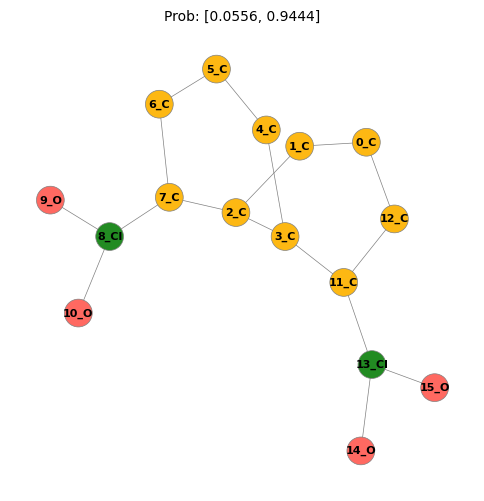

In [39]:
from utils import *
gcn_prob = gcn_prob.detach().numpy().squeeze().tolist()
gcn_prob = [round(x, 4) for x in gcn_prob]
visualize_mutag_graph(G, pos = nx.kamada_kawai_layout(G), title=f"Prob: {gcn_prob}")

In [86]:
graph_0 = [dataset[i] for i in range(len(dataset)) if dataset[i].y == 0]
graph_1 = [dataset[i] for i in range(len(dataset)) if dataset[i].y == 1]

len(graph_0), len(graph_1)

(63, 125)

### Visualize graph 0 - MUTAG ###

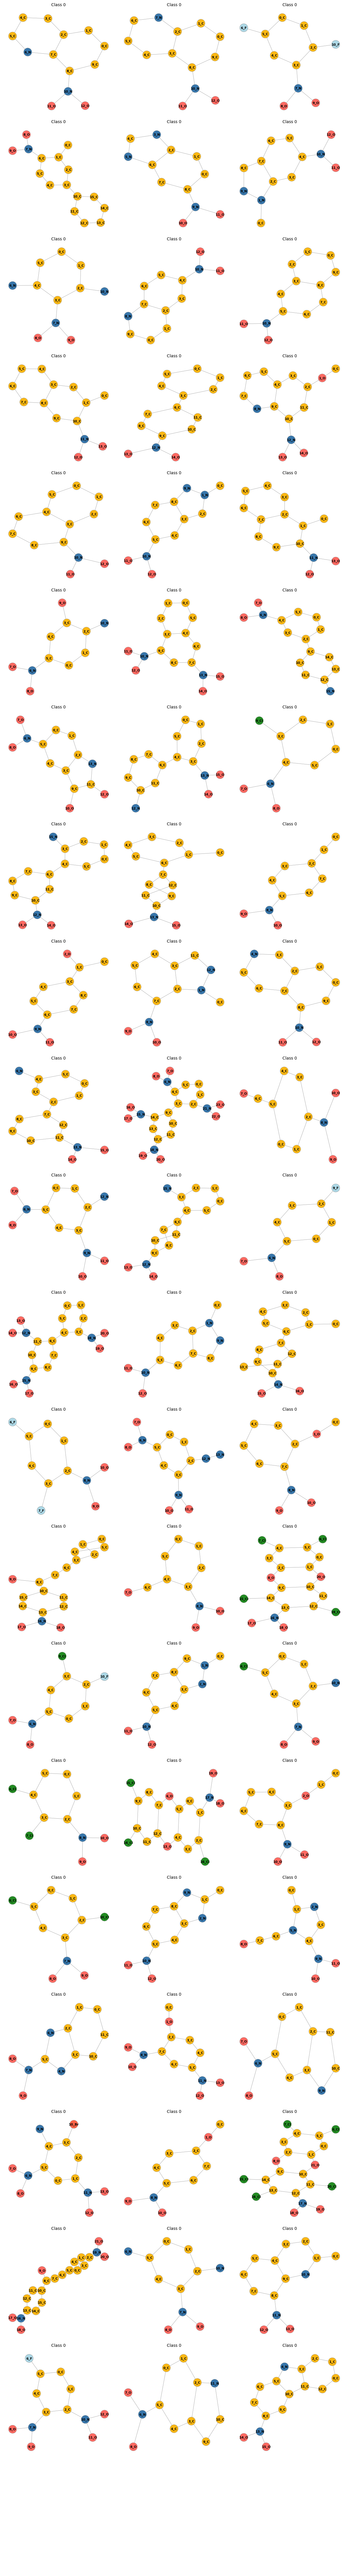

In [103]:
import math
import matplotlib.pyplot as plt
_original_show = plt.show
plt.show = lambda *args, **kwargs: None

total_graphs = len(graph_0) + 1
cols = 3
rows = math.ceil(total_graphs / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4))
axes = axes.flatten()

for idx in range(len(graph_0)):
    G = to_networkx(graph_0[idx], to_undirected=True, node_attrs=["x"])
    title = f"Class 0"
    ax = axes[idx]
    pos = nx.kamada_kawai_layout(G)
    visualize_mutag_graph(G, pos=pos, ax=ax, title=title)
    

for ax in axes[len(graph_0):]:
    ax.axis("off")

plt.tight_layout()
plt.show = _original_show
plt.show()




In [104]:
_original_show = plt.show
plt.show = lambda *args, **kwargs: None

total_graphs = len(graph_1) + 1
cols = 3
rows = math.ceil(total_graphs / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4))
axes = axes.flatten()

for idx in range(len(graph_1)):
    G = to_networkx(graph_1[idx], to_undirected=True, node_attrs=["x"])
    title = f"Class 1"
    ax = axes[idx]
    pos = nx.kamada_kawai_layout(G)
    visualize_mutag_graph(G, pos=pos, ax=ax, title=title)
    

for ax in axes[len(graph_1):]:
    ax.axis("off")

plt.tight_layout()
plt.show = _original_show
plt.show()